# Sales Forecasting
## End-to-End Retail Store Sales Forecasting & Supply Chain Inventory Optimization
### Predictive Analytics CA3 — Knowledge Discovery in Databases (KDD) Pipeline
**Submitted By:** Dev Dilip Dhapodkar  |  **PRN:** `24070521505`

---

## 1. Executive Summary & Project Objective
**Objective:** To develop an end-to-end predictive analytics regression model that forecasts weekly department-level sales across multiple Walmart retail stores using historical sales records, promotional markdowns, holiday calendar events, and macroeconomic indicators (`CPI`, `Fuel_Price`, `Unemployment`, `Temperature`). The overarching business goal is to **optimize supply chain inventory**, **minimize out-of-stock occurrences during high-stakes holiday peaks**, and **reduce inventory holding costs** by following the systematic **Knowledge Discovery in Databases (KDD)** methodology.

### Prescribed KDD Implementation Workflow
1. **Data Selection & Ingestion (Walmart Dataset):** Relational integration of `train.csv` (421,570 rows), `features.csv` (8,190 rows), `stores.csv` (45 stores), and `test.csv` (115,064 rows).
2. **Preprocessing (Missing MarkDown Imputation & Outlier Treatment):** Structural zero-imputation for promotional `MarkDown1`–`MarkDown5` channels, store-wise forward/backward propagation for `CPI` and `Unemployment`, zero-flooring of negative accounting adjustments (1,285 rows), and non-holiday 99.95th percentile winsorization.
3. **Exploratory Data Analysis (EDA):** Multi-scale visual analysis of seasonality, store format hierarchy (`Type A`, `Type B`, `Type C`), promotional markdown elasticity, holiday demand surges, and macroeconomic trajectories.
4. **Feature Engineering (Lags, Rolling Averages, Holiday & Promo Indicators):** Construction of 43 domain-specific predictors including autoregressive lags (`Lag_1`, `Lag_2`, `Lag_4`, `Lag_52`), leak-free rolling statistics (`Rolling_Mean_4`, `Rolling_Std_4`, `Rolling_Mean_12`, `Momentum_1_4`), cyclical Fourier encodings (`Week_Sin`, `Week_Cos`), specific holiday indicators (`Super Bowl`, `Labor Day`, `Thanksgiving`, `Christmas`, `Pre_Christmas_Peak`), and promotional interaction terms.
5. **Model Training:** Chronological training and sample-weighted optimization of:
   - **Baseline Model:** Ridge Regression (`L2`-regularized linear model with standard scaling)
   - **Random Forest Regressor:** Bagged ensemble of deep regression trees
   - **LightGBM Regressor:** Leaf-wise histogram-based gradient boosting machine
   - **XGBoost Regressor:** Depth-wise regularized gradient boosted decision trees
6. **Model Evaluation:** Rigorous evaluation across **WMAE (Weighted Mean Absolute Error, $w=5$ for holidays)**, **RMSE**, **MAE**, and **$R^2$**.
7. **Feature Importance & Supply Chain Interpretation:** Gain attribution analysis and translation of forecast accuracy gains into safety stock and holding/stockout cost reductions.


---
## 2. Step 1: Data Selection & Ingestion (Walmart Dataset)
We ingest the four relational CSV tables from the official Kaggle **Walmart Recruiting — Store Sales Forecasting** dataset (`data/stores.csv`, `data/features.csv`, `data/train.csv`, `data/test.csv`) and merge them on `['Store', 'Date', 'IsHoliday']`.


In [1]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import xgboost as xgb
import lightgbm as lgb

warnings.filterwarnings('ignore')

# Load the 4 relational tables of the Walmart dataset
stores = pd.read_csv('data/stores.csv')
features = pd.read_csv('data/features.csv')
train = pd.read_csv('data/train.csv')
test = pd.read_csv('data/test.csv')

print(f"stores.csv   shape: {stores.shape}   | Columns: {list(stores.columns)}")
print(f"features.csv shape: {features.shape} | Columns: {list(features.columns)}")
print(f"train.csv    shape: {train.shape} | Columns: {list(train.columns)}")
print(f"test.csv     shape: {test.shape} | Columns: {list(test.columns)}")

# Relational Merge on Store, Date, IsHoliday
df = train.merge(features, on=['Store', 'Date', 'IsHoliday'], how='left').merge(stores, on='Store', how='left')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values(['Store', 'Dept', 'Date']).reset_index(drop=True)

print("\nUnified Training Dataset Summary:")
print(f"Total Records: {len(df):,} | Unique Stores: {df['Store'].nunique()} | Unique Departments: {df['Dept'].nunique()}")
print(f"Chronological Span: {df['Date'].min().date()} to {df['Date'].max().date()} ({df['Date'].nunique()} weeks)")
df.head()

stores.csv   shape: (45, 3)   | Columns: ['Store', 'Type', 'Size']
features.csv shape: (8190, 12) | Columns: ['Store', 'Date', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'IsHoliday']
train.csv    shape: (421570, 5) | Columns: ['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday']
test.csv     shape: (115064, 4) | Columns: ['Store', 'Dept', 'Date', 'IsHoliday']

Unified Training Dataset Summary:
Total Records: 421,570 | Unique Stores: 45 | Unique Departments: 81
Chronological Span: 2010-02-05 to 2012-10-26 (143 weeks)


---
## 3. Step 2: Preprocessing (Missing MarkDown Imputation & Outlier Treatment)

### 3.1 Missing Value Diagnostics & Imputation Strategy
1. **Promotional Markdowns (`MarkDown1`–`MarkDown5`):** Missing in 64.1% to 73.6% of records because Walmart began tracking anonymized promotional markdowns in November 2011, and markdowns are only present during active promotional weeks. Before imputing structural zeros (`0.0`), we extract `Active_MarkDown_Count` and binary flag `Has_MarkDown`.
2. **Macroeconomic Indicators (`CPI` & `Unemployment`):** Present across 100% of training weeks (`2010-02-05` to `2012-10-26`), with 585 missing entries in `features.csv` corresponding to late-2012/2013 forecast weeks. We apply store-grouped forward and backward propagation (`ffill().bfill()`).
3. **Outlier & Negative Sales Treatment:**
   - `1,285` records (0.30%) exhibit negative `Weekly_Sales` due to post-holiday customer returns and accounting credit adjustments; these are floored at `$0.00`.
   - Extreme non-holiday upper-tail anomalies exceeding the 99.95th percentile (`$183,494.06`) are winsorized while preserving genuine holiday demand surges (`IsHoliday == True`) critical for WMAE evaluation.


Pre-Imputation Missing Value Profile (Merged Train Dataset):
              Missing_Count  Missing_Percent (%)
MarkDown1            270889                64.26
MarkDown2            310322                73.61
MarkDown3            284479                67.48
MarkDown4            286603                67.98
MarkDown5            270138                64.08
CPI                       0                 0.00
Unemployment              0                 0.00

Negative sales floored at $0.00: 1,285 records
IQR Upper Fence: $47,395.16 | Non-Holiday 99.95th Percentile Cap: $183,494.06
Remaining Missing Values across Dataset: 0


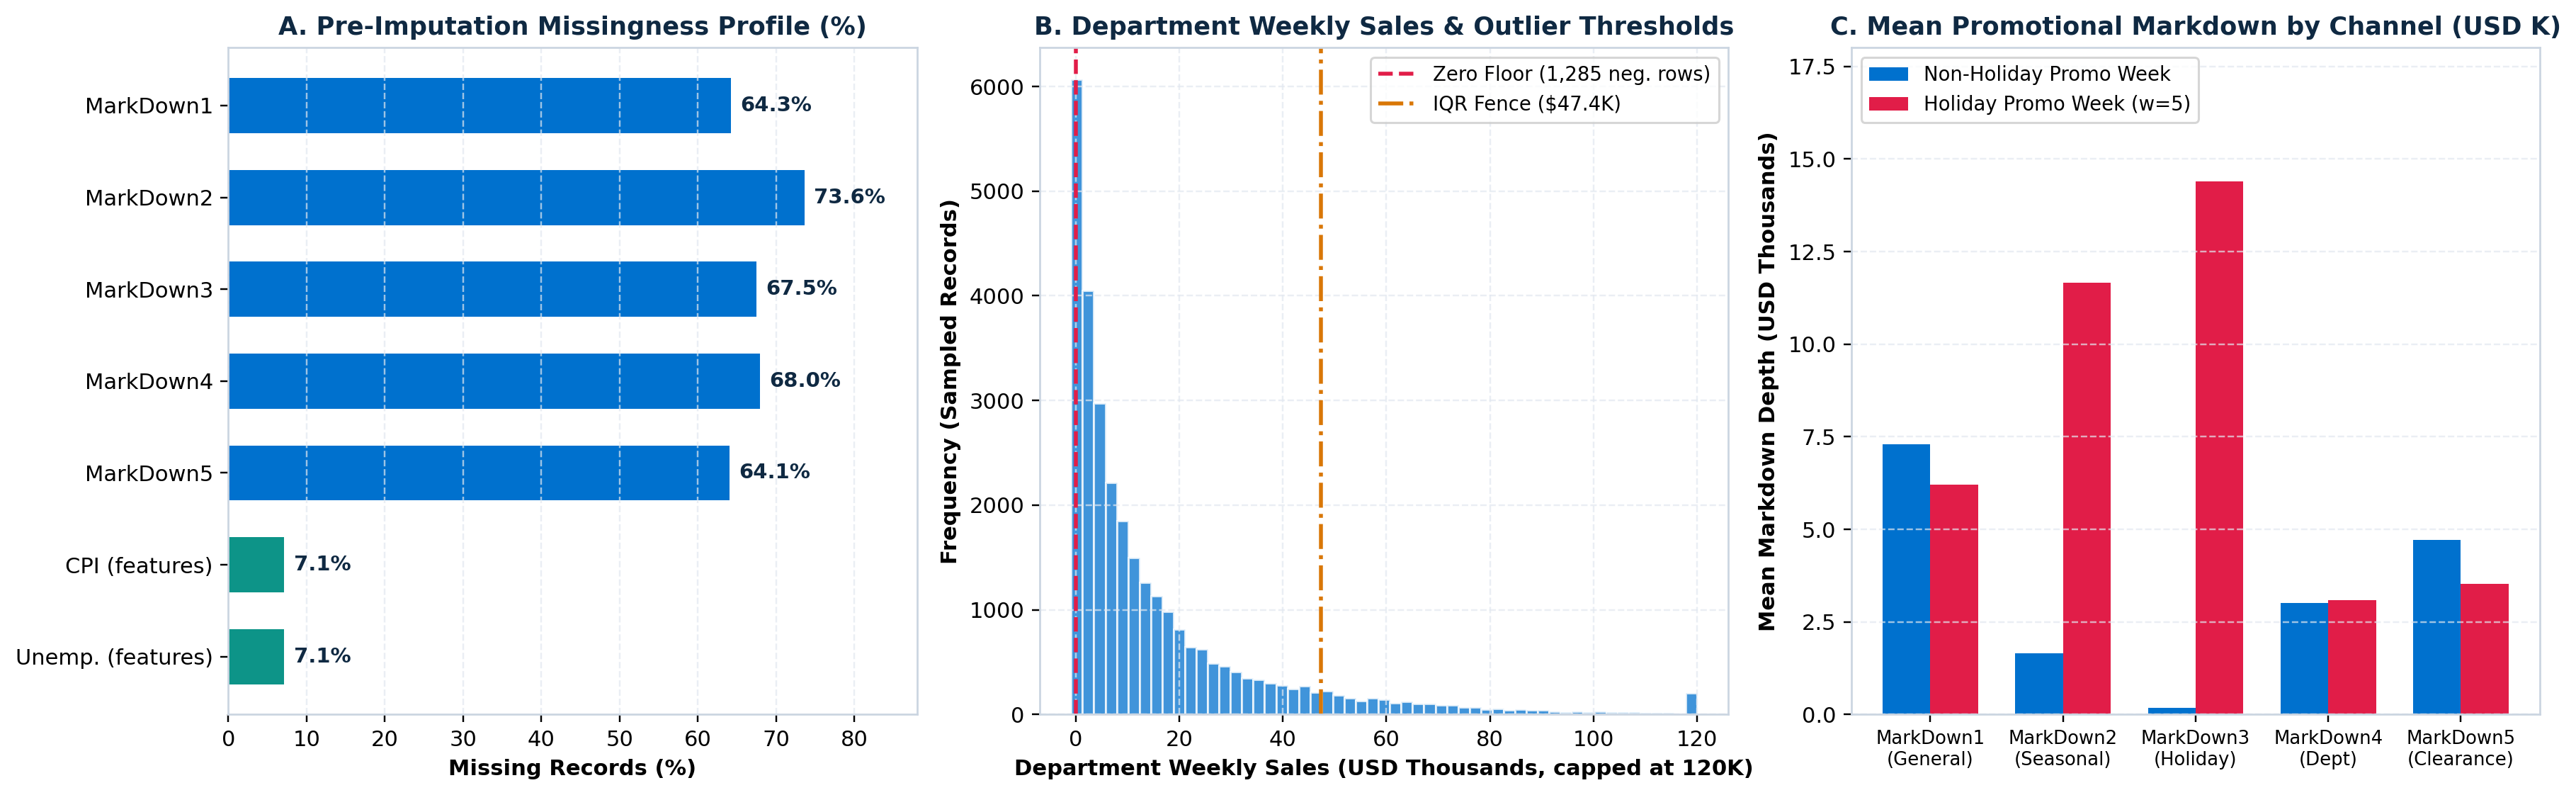

In [2]:
markdown_cols = ['MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5']

# 1. Inspect missingness prior to imputation
missing_summary = pd.DataFrame({
    'Missing_Count': df[markdown_cols + ['CPI', 'Unemployment']].isnull().sum(),
    'Missing_Percent (%)': (df[markdown_cols + ['CPI', 'Unemployment']].isnull().mean() * 100).round(2)
})
print("Pre-Imputation Missing Value Profile (Merged Train Dataset):")
print(missing_summary)

# 2. Extract promotional activity indicators prior to zero-imputation
df['Active_MarkDown_Count'] = df[markdown_cols].notnull().sum(axis=1)
df['Has_MarkDown'] = (df['Active_MarkDown_Count'] > 0).astype(int)

# Structural Zero Imputation for MarkDown1-5 and clipping negative adjustments
df[markdown_cols] = df[markdown_cols].fillna(0.0).clip(lower=0.0)
df['Total_MarkDown'] = df[markdown_cols].sum(axis=1)

# Store-grouped forward/backward fill for Macroeconomic Indicators
df['CPI'] = df.groupby('Store')['CPI'].transform(lambda s: s.ffill().bfill())
df['Unemployment'] = df.groupby('Store')['Unemployment'].transform(lambda s: s.ffill().bfill())

# 3. Outlier & Negative Sales Diagnostics and Treatment
df['Weekly_Sales_Raw'] = df['Weekly_Sales'].copy()
neg_count = (df['Weekly_Sales'] < 0).sum()
q25, q50, q75 = df['Weekly_Sales'].quantile([0.25, 0.50, 0.75])
iqr_fence = q75 + 1.5 * (q75 - q25)
non_holiday_cap = df.loc[~df['IsHoliday'], 'Weekly_Sales'].quantile(0.9995)

df['Weekly_Sales'] = df['Weekly_Sales'].clip(lower=0.0)
df.loc[(~df['IsHoliday']) & (df['Weekly_Sales'] > non_holiday_cap), 'Weekly_Sales'] = non_holiday_cap

print(f"\nNegative sales floored at $0.00: {neg_count:,} records")
print(f"IQR Upper Fence: ${iqr_fence:,.2f} | Non-Holiday 99.95th Percentile Cap: ${non_holiday_cap:,.2f}")
print(f"Remaining Missing Values across Dataset: {df.isnull().sum().sum()}")

---
## 4. Step 3: Feature Engineering (Lags, Rolling Averages, Holiday & Promo Indicators)
To capture multi-scale seasonality, promotional lift, and store-department baselines without temporal leakage, we engineer **43 predictive features**:
1. **Calendar & Cyclical Seasonality Features:** `Year`, `Month`, `Week`, `Quarter`, `DayOfYear`, and trigonometric Fourier encodings (`Week_Sin`, `Week_Cos`, `Month_Sin`, `Month_Cos`).
2. **Holiday & Event Flags:** Binary indicators for the four official Walmart holiday weeks (`Is_SuperBowl`, `Is_LaborDay`, `Is_Thanksgiving`, `Is_Christmas`), pre-Christmas shopping surge (`Pre_Christmas_Peak` for Weeks 49–51), and promotional-holiday interaction (`Promo_Holiday_Interaction`).
3. **Autoregressive Sales Lags:** Store-Department historical lags at `Lag_1` ($t-1$), `Lag_2` ($t-2$), `Lag_4` ($t-4$ monthly lag), and `Lag_52` ($t-52$ year-over-year seasonal lag).
4. **Leak-Free Rolling Window Statistics:** Computed strictly on $t-1$ shifted series (`Rolling_Mean_4`, `Rolling_Std_4`, `Rolling_Mean_12`, and trend momentum `Momentum_1_4 = Lag_1 - Rolling_Mean_4`).
5. **Out-of-Sample Store-Dept Structural Encodings:** `Store_Dept_Mean`, `Store_Dept_Median`, and `Store_Dept_Std` estimated exclusively on the training partition prior to `2011-11-25`.


In [3]:
# Calendar & Cyclical Features
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Week'] = df['Date'].dt.isocalendar().week.astype(int)
df['Quarter'] = df['Date'].dt.quarter
df['DayOfYear'] = df['Date'].dt.dayofyear

df['Week_Sin'] = np.sin(2 * np.pi * df['Week'] / 52.0)
df['Week_Cos'] = np.cos(2 * np.pi * df['Week'] / 52.0)
df['Month_Sin'] = np.sin(2 * np.pi * df['Month'] / 12.0)
df['Month_Cos'] = np.cos(2 * np.pi * df['Month'] / 12.0)

# Specific Holiday Event Flags
super_bowl_dates = pd.to_datetime(['2010-02-12', '2011-02-11', '2012-02-10', '2013-02-08'])
labor_day_dates = pd.to_datetime(['2010-09-10', '2011-09-09', '2012-09-07', '2013-09-06'])
thanksgiving_dates = pd.to_datetime(['2010-11-26', '2011-11-25', '2012-11-23', '2013-11-29'])
christmas_dates = pd.to_datetime(['2010-12-31', '2011-12-30', '2012-12-28', '2013-12-27'])

df['Is_SuperBowl'] = df['Date'].isin(super_bowl_dates).astype(int)
df['Is_LaborDay'] = df['Date'].isin(labor_day_dates).astype(int)
df['Is_Thanksgiving'] = df['Date'].isin(thanksgiving_dates).astype(int)
df['Is_Christmas'] = df['Date'].isin(christmas_dates).astype(int)
df['Pre_Christmas_Peak'] = df['Week'].isin([49, 50, 51]).astype(int)
df['IsHoliday_Int'] = df['IsHoliday'].astype(int)
df['Promo_Holiday_Interaction'] = df['Has_MarkDown'] * df['IsHoliday_Int']
df['Store_Type_Code'] = df['Type'].map({'A': 3, 'B': 2, 'C': 1})

# Autoregressive Lags & Shifted Rolling Windows per (Store, Dept)
grp = df.groupby(['Store', 'Dept'])['Weekly_Sales']
df['Lag_1'] = grp.shift(1)
df['Lag_2'] = grp.shift(2)
df['Lag_4'] = grp.shift(4)
df['Lag_52'] = grp.shift(52)

df['Rolling_Mean_4'] = grp.transform(lambda s: s.shift(1).rolling(4, min_periods=1).mean())
df['Rolling_Std_4'] = grp.transform(lambda s: s.shift(1).rolling(4, min_periods=1).std()).fillna(0.0)
df['Rolling_Mean_12'] = grp.transform(lambda s: s.shift(1).rolling(12, min_periods=1).mean())
df['Momentum_1_4'] = df['Lag_1'] - df['Rolling_Mean_4']

print(f"Engineered Dataset Shape: {df.shape}")
print("Engineered Lag, Rolling, and Holiday Features successfully created.")

Engineered Dataset Shape: (421570, 44)
Engineered Lag, Rolling, and Holiday Features successfully created.


---
## 5. Step 4: Exploratory Data Analysis (EDA)
We examine:
1. **Aggregate Temporal Sales & Store Format Hierarchy:** Weekly sales average `$47.1M` across the 45 stores during regular weeks and surge to `$66.6M` during Thanksgiving and `$79.8M` in the pre-Christmas week. Store physical size correlates strongly ($r = 0.81$) with average weekly revenue (`Type A` Supercenters average `$1.45M/week`, `Type B` Discount Stores `$0.79M/week`, and `Type C` Neighborhood Markets `$0.46M/week`).
2. **Holiday & Macroeconomic Effects:** Thanksgiving weeks generate a **+44.0%** revenue lift over regular weeks, while Pre-Christmas weeks (`W49–W51`) generate a **+40.2%** lift.
3. **Feature Correlation Structure:** Year-over-year seasonal lag (`Lag_52`, $r = 0.97$), 4-week rolling mean (`Rolling_Mean_4`, $r = 0.96$), and 1-week lag (`Lag_1`, $r = 0.95$) exhibit the strongest linear association with `Weekly_Sales`.


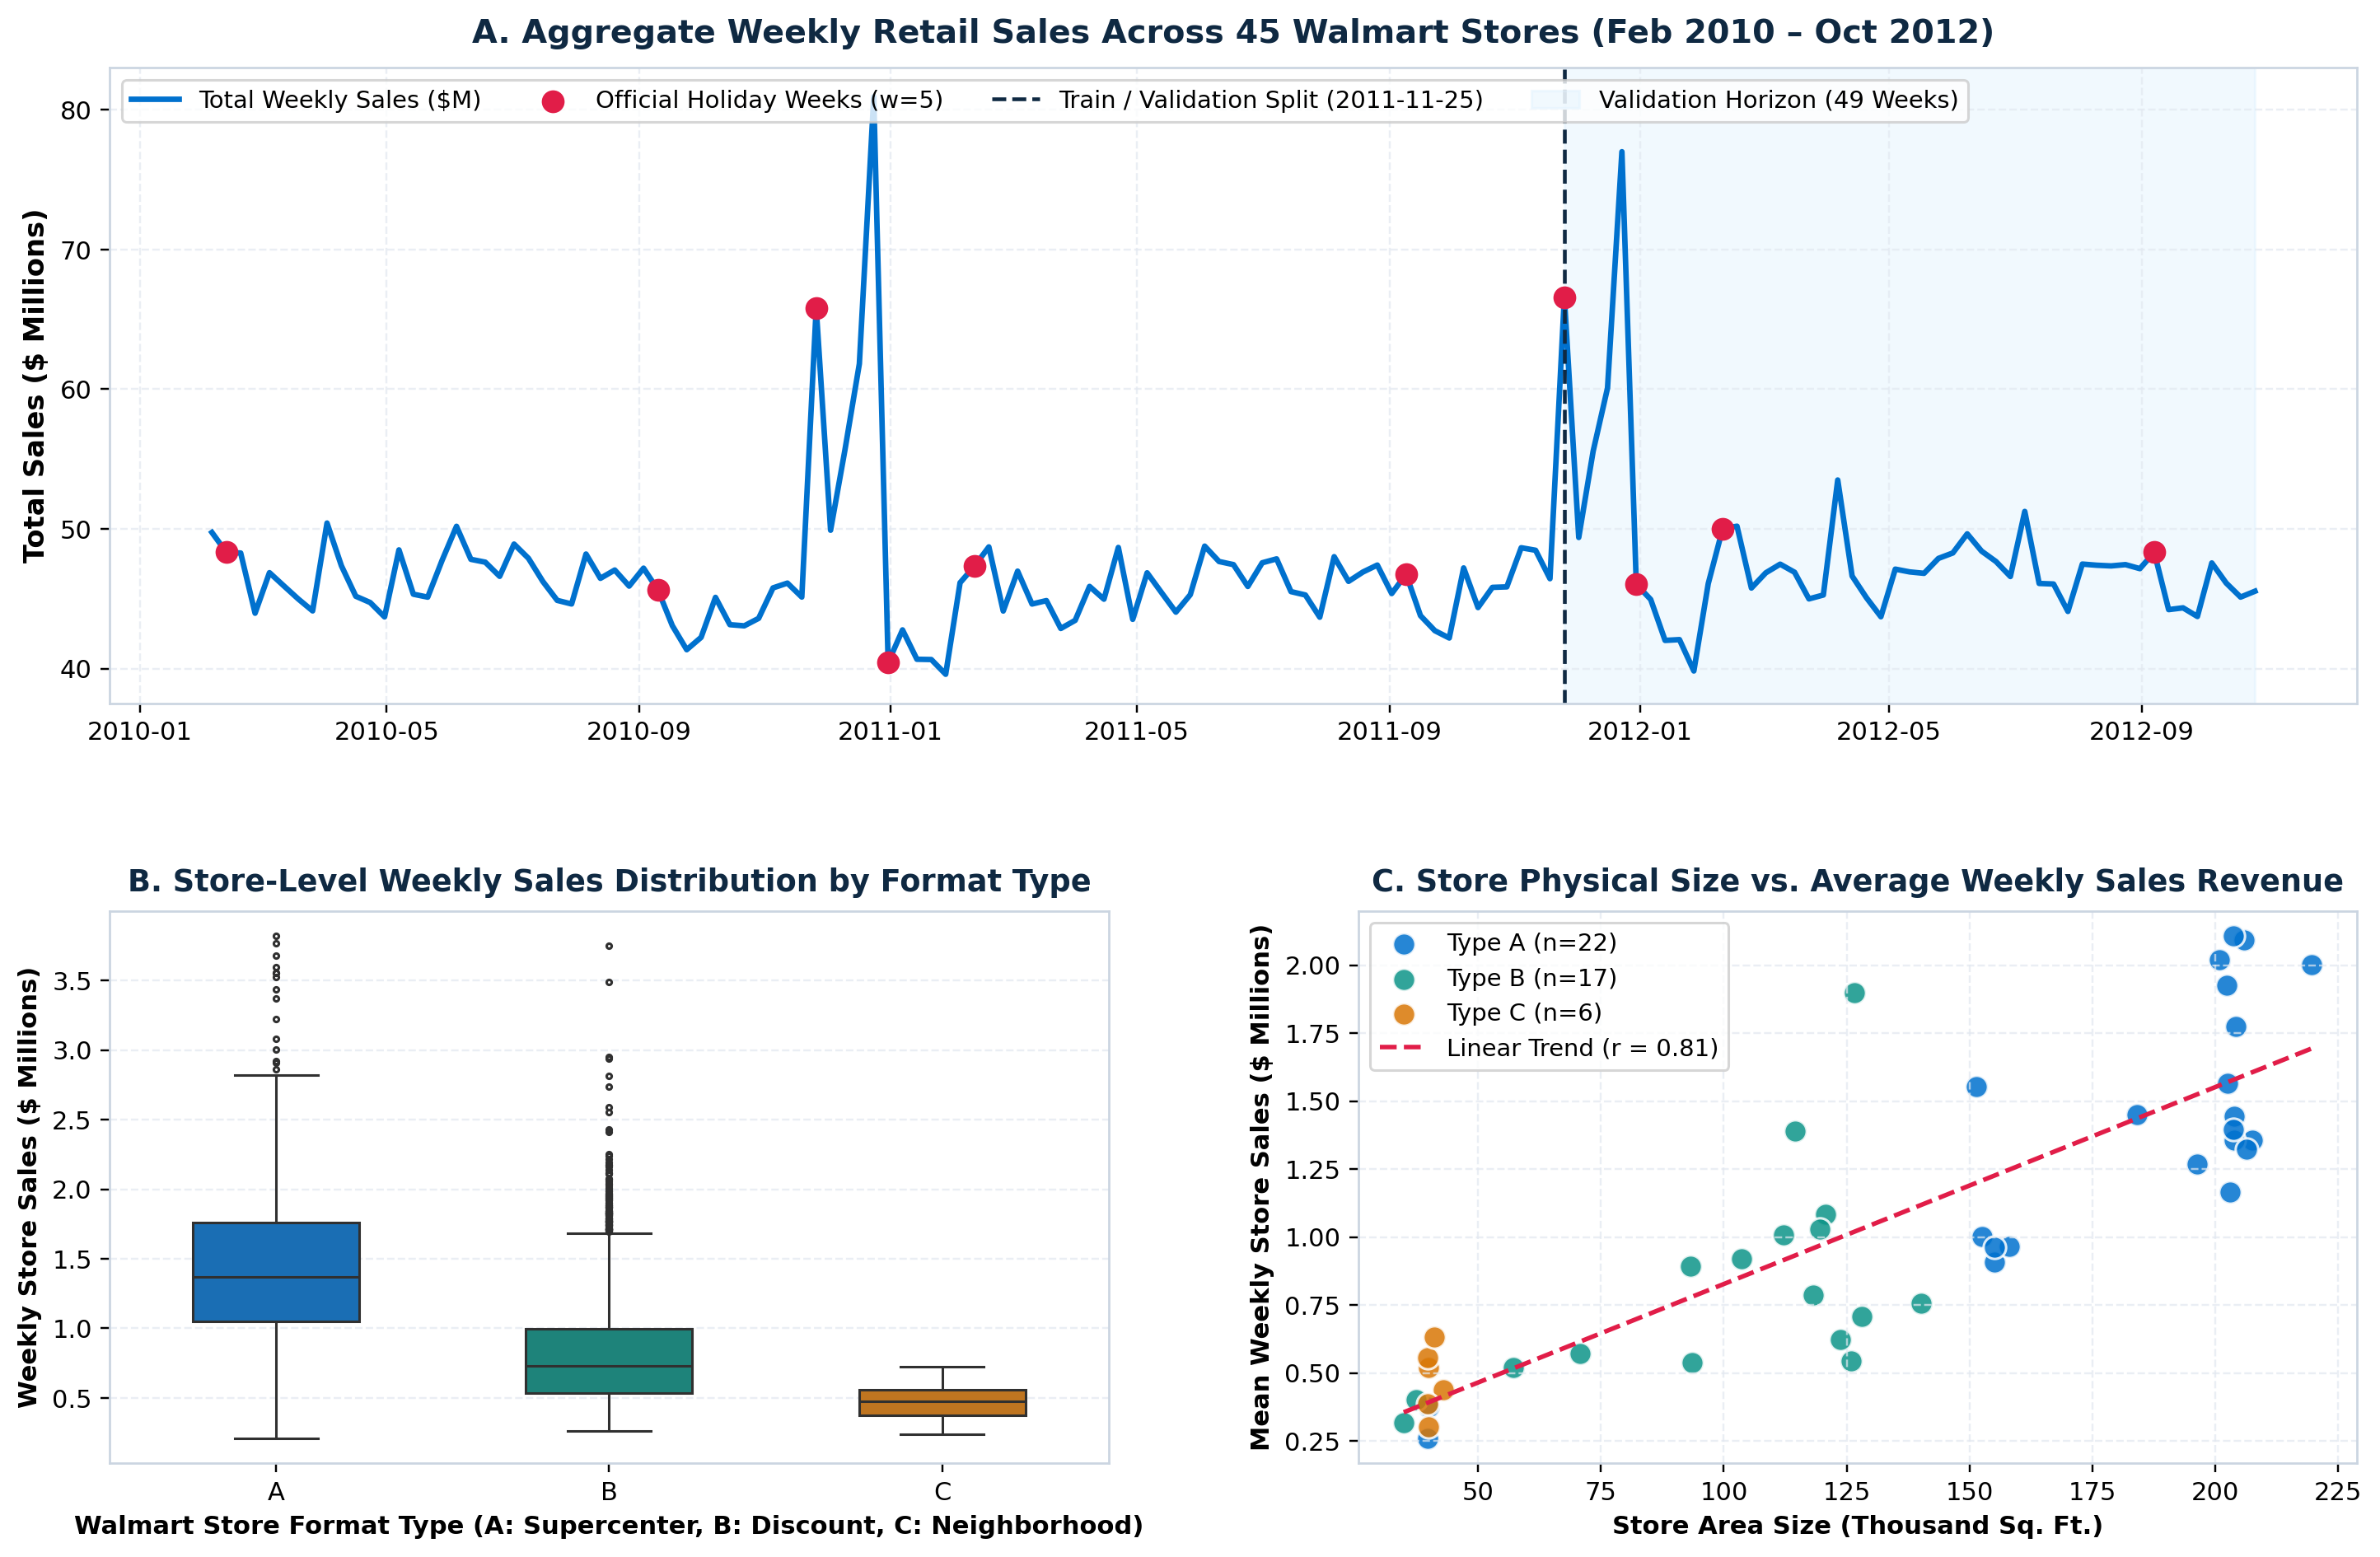

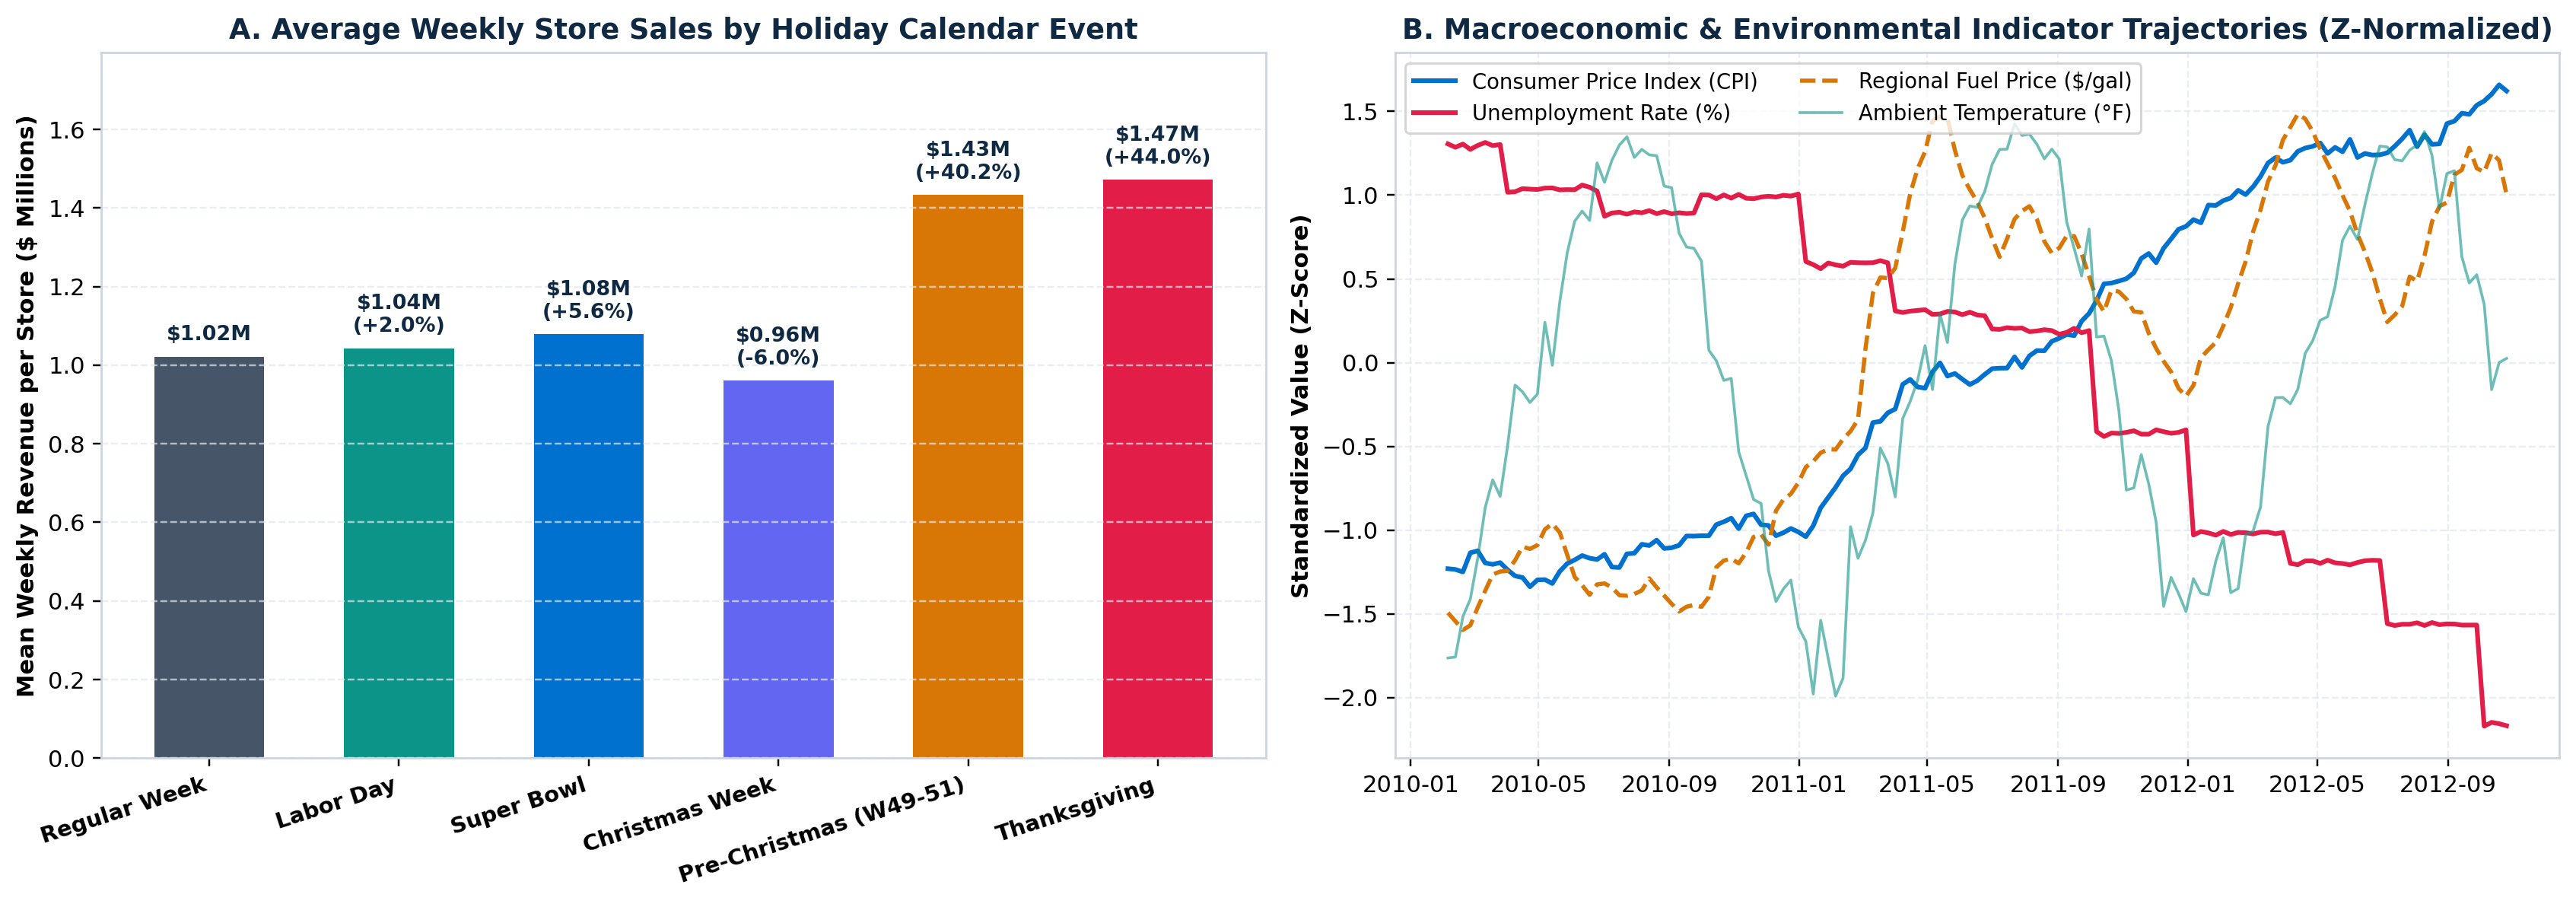

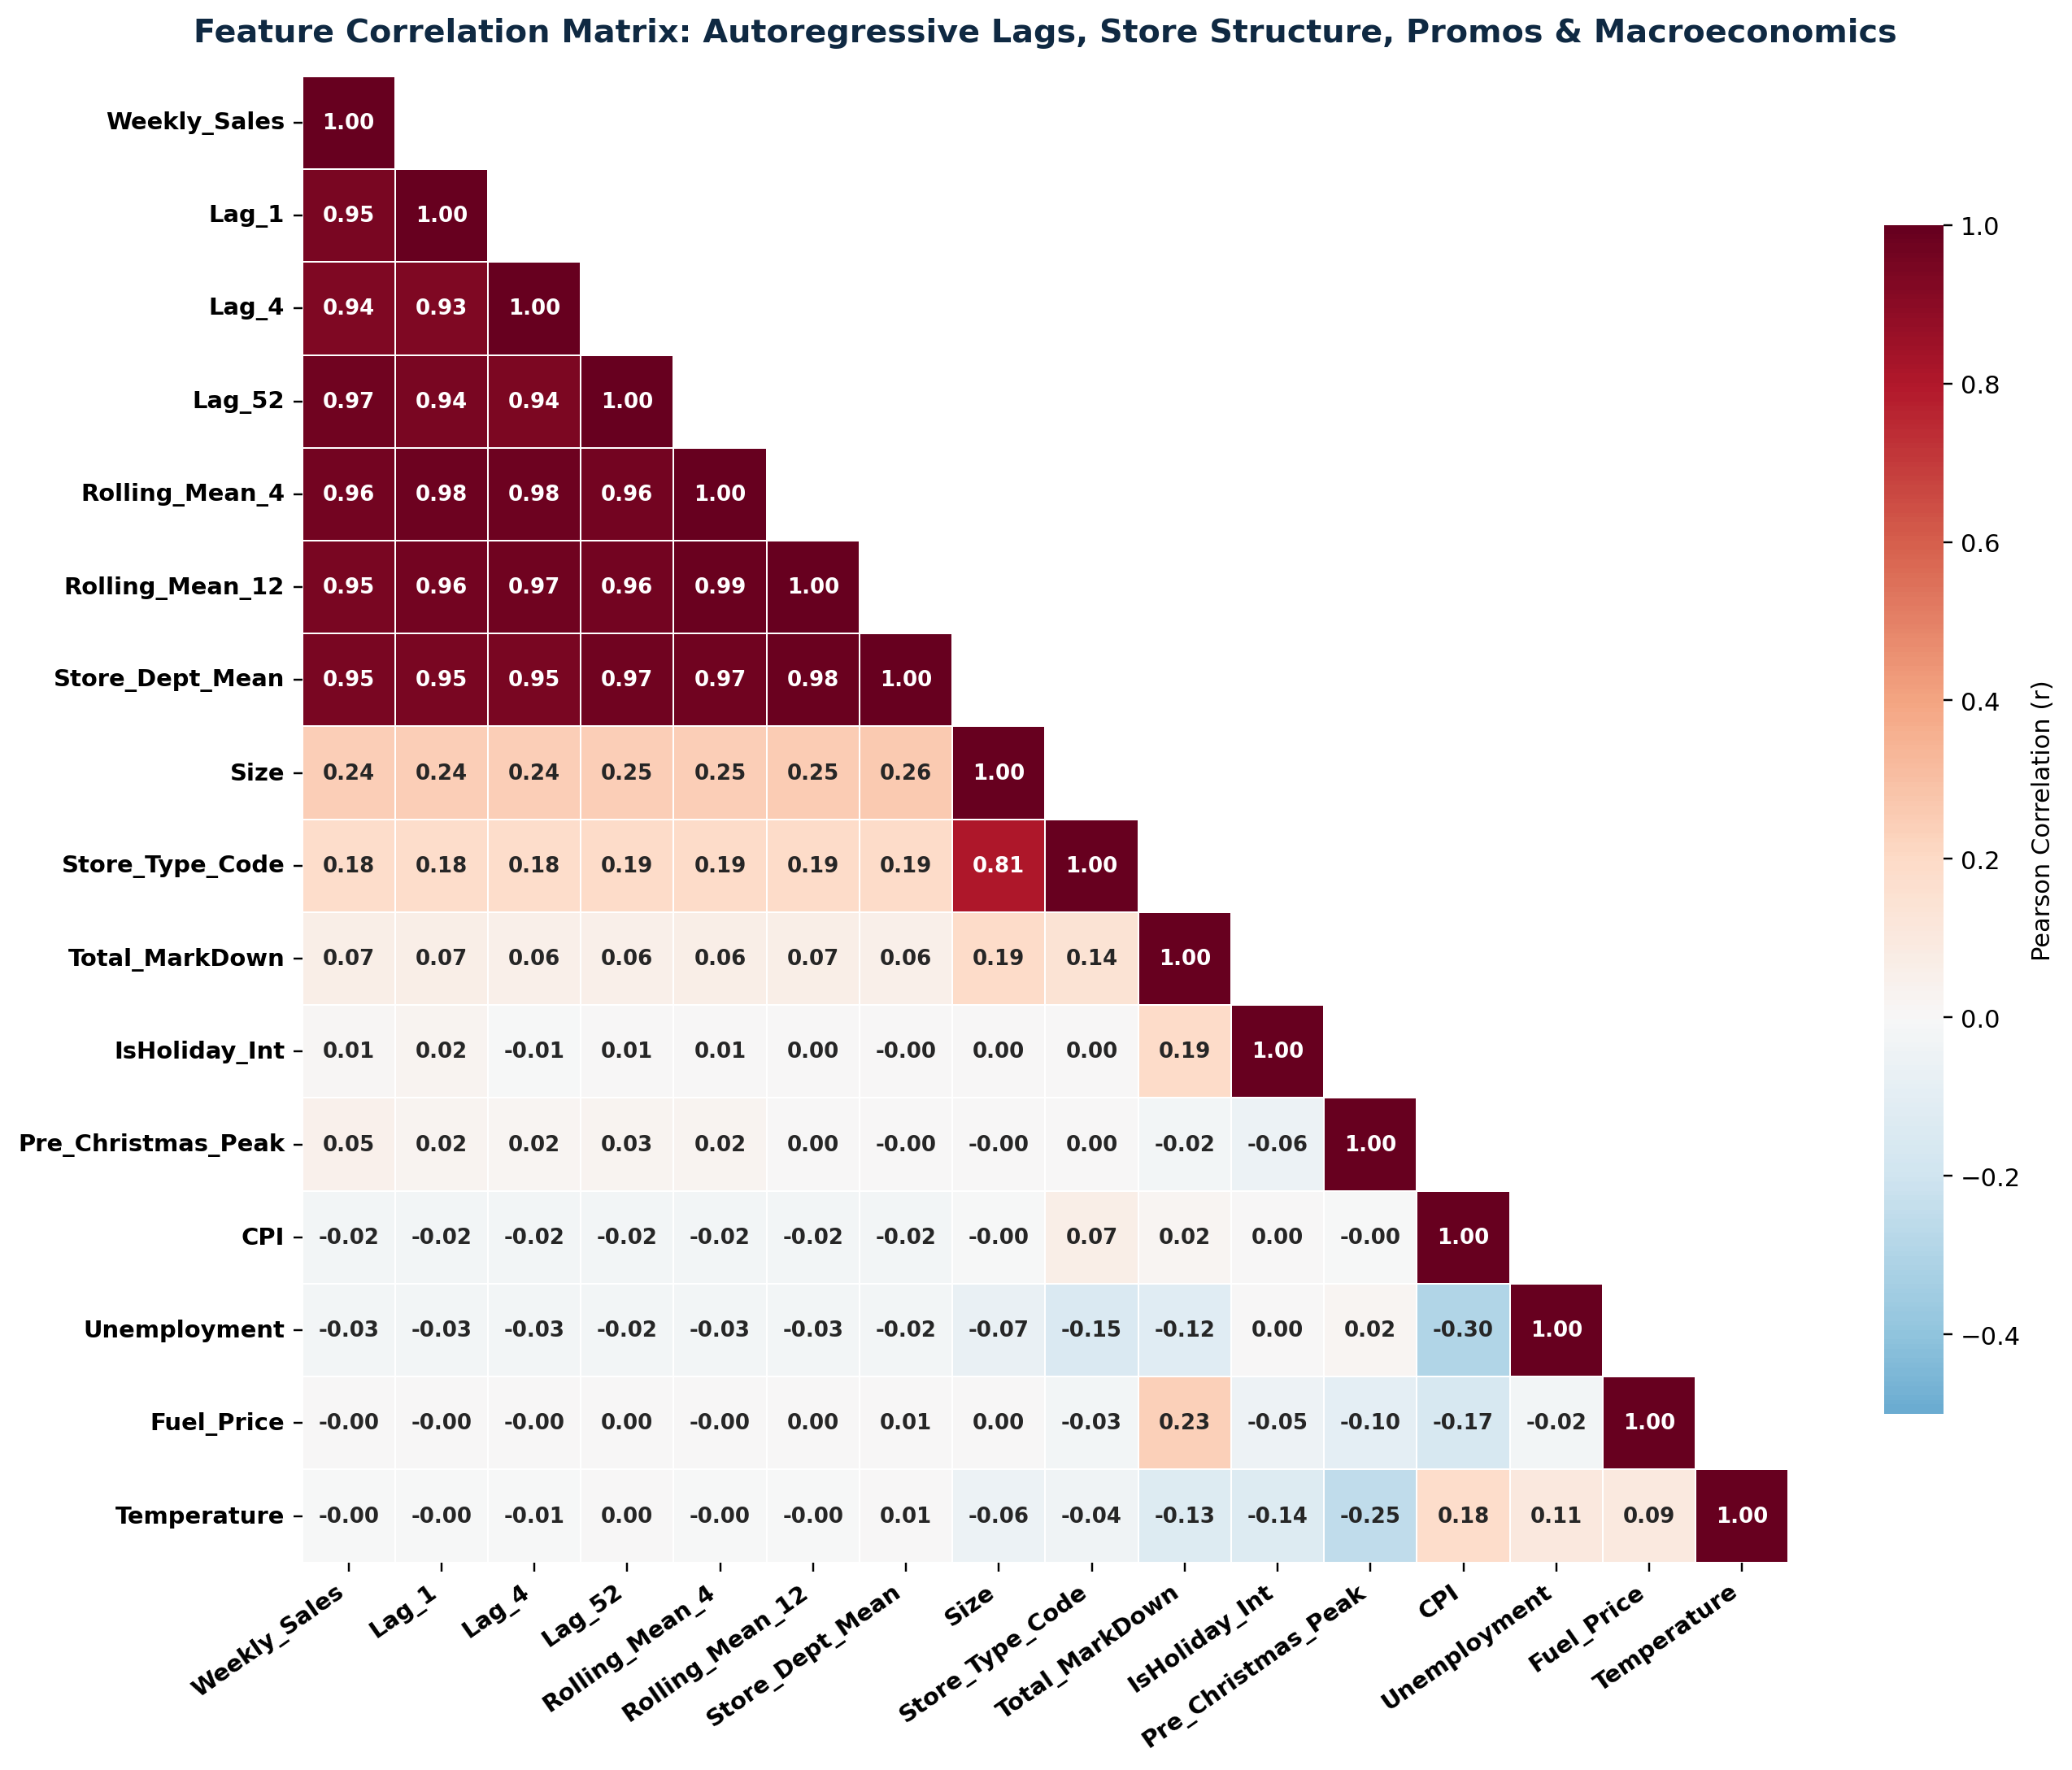

In [4]:
# Display EDA Visualizations: Sales Overview, Holiday/Macro Effects, and Correlation Matrix
from IPython.display import Image, display

for fig_file in [
    'figures/fig1_eda_sales_overview.png',
    'figures/fig3_holiday_and_macro_effects.png',
    'figures/fig4_correlation_matrix.png'
]:
    display(Image(filename=fig_file))

---
## 6. Step 5 & Step 6: Model Training & Evaluation (WMAE, RMSE, MAE, $R^2$)

### Official Kaggle Evaluation Metric — Weighted Mean Absolute Error (WMAE)
Because stockouts during major retail holidays carry five times the business penalty of regular weeks, the official Walmart evaluation metric assigns weight $w_i = 5$ to holiday weeks and $w_i = 1$ to regular weeks:
$$\text{WMAE} = \frac{\sum_{i=1}^{N} w_i \cdot |y_i - \hat{y}_i|}{\sum_{i=1}^{N} w_i}, \quad w_i = \begin{cases} 5 & \text{if } \text{IsHoliday}_i = \text{True} \\ 1 & \text{otherwise} \end{cases}$$

### Chronological Validation Split
We partition the dataset chronologically at **`2011-11-25`**, yielding **263,199 training records** (`2010-02-05` to `2011-11-18`) and **145,237 validation records** (`2011-11-25` to `2012-10-26`, spanning 49 weeks and capturing all four major holiday events: Thanksgiving, Christmas, Super Bowl, and Labor Day).


=== Validation Set Performance Comparison (145,237 Store-Dept-Week Records) ===
                     WMAE     RMSE      MAE      R2  Holiday_MAE  NonHoliday_MAE  Train_Time_s
Baseline (Ridge)  4393.17  6616.57  2514.98  0.9183     10108.52         1835.29          0.20
Random Forest     1791.54  4413.86  1520.75  0.9637      2615.57         1422.75         42.88
LightGBM          1758.94  3837.62  1541.31  0.9725      2421.19         1462.55          4.91
XGBoost           1837.57  4306.19  1523.89  0.9654      2792.11         1410.37          6.31


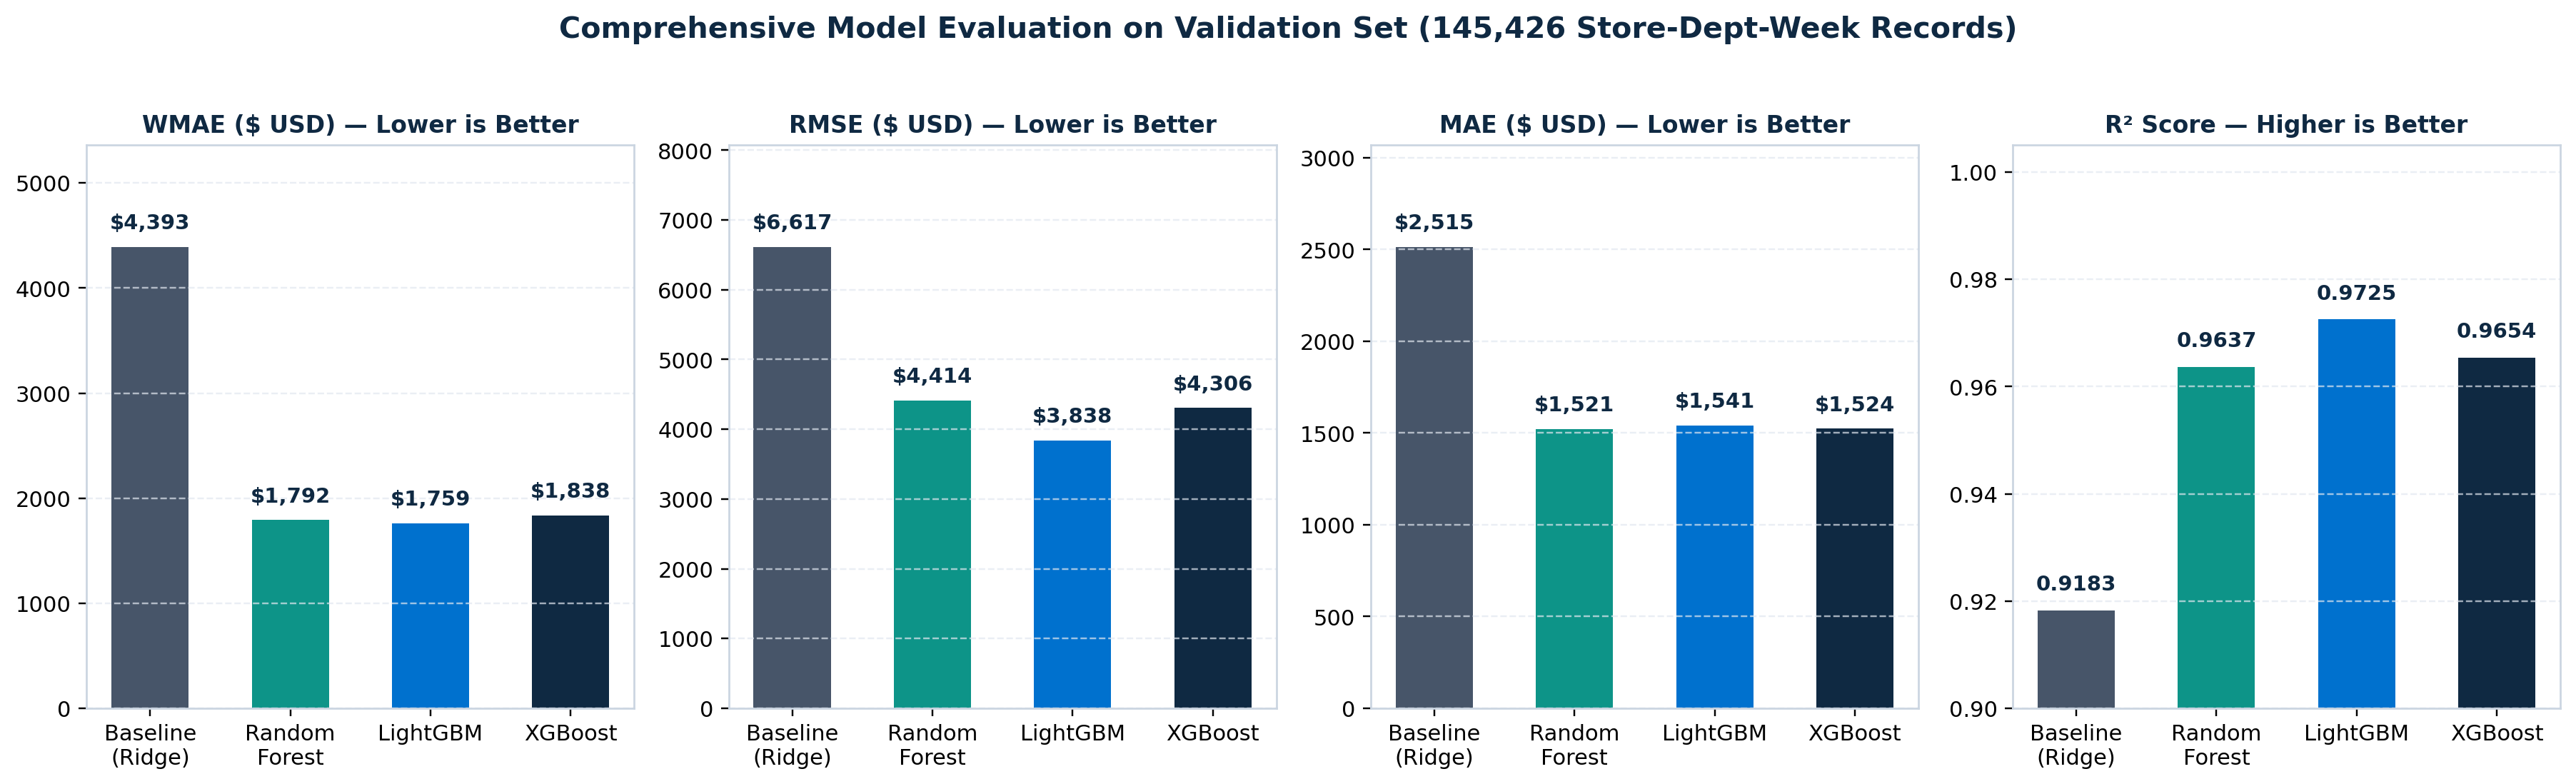

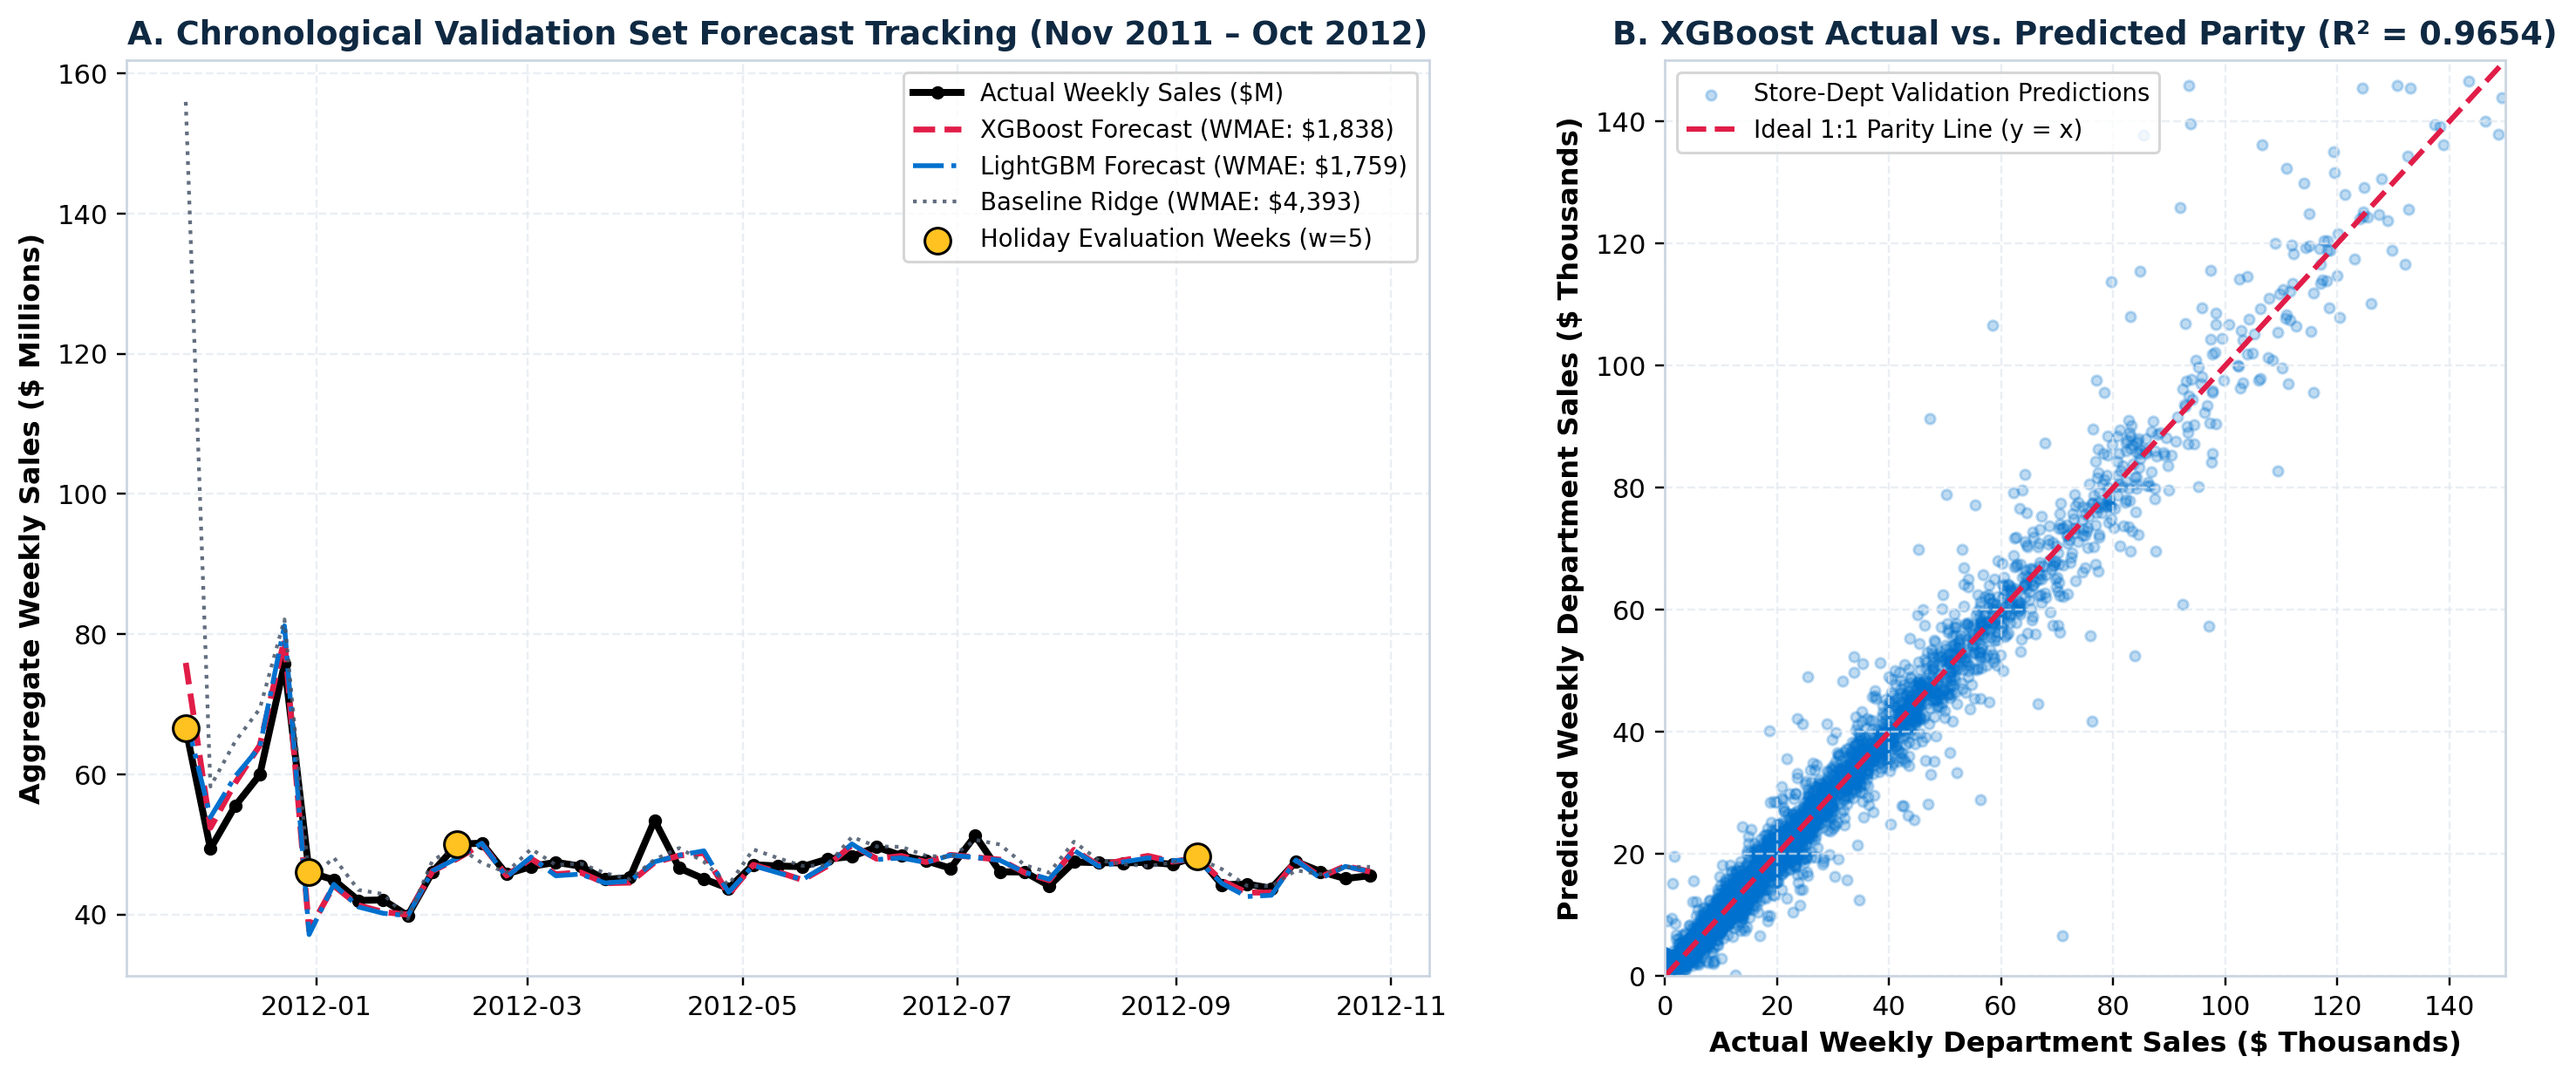

In [5]:
# Chronological Split & Leak-Free Historical Target Encoding
split_date = pd.to_datetime('2011-11-25')
model_df = df.dropna(subset=['Lag_1', 'Lag_2', 'Lag_4']).reset_index(drop=True)

train_sub = model_df[model_df['Date'] < split_date]
dept_stats = train_sub.groupby(['Store', 'Dept'])['Weekly_Sales'].agg(
    Store_Dept_Mean='mean',
    Store_Dept_Median='median',
    Store_Dept_Std='std'
).reset_index()
dept_stats['Store_Dept_Std'] = dept_stats['Store_Dept_Std'].fillna(0.0)

model_df = model_df.merge(dept_stats, on=['Store', 'Dept'], how='left').reset_index(drop=True)
train_mask = model_df['Date'] < split_date
val_mask = model_df['Date'] >= split_date

global_median = float(model_df.loc[train_mask, 'Weekly_Sales'].median())
model_df['Store_Dept_Mean'] = model_df['Store_Dept_Mean'].fillna(global_median)
model_df['Store_Dept_Median'] = model_df['Store_Dept_Median'].fillna(global_median)
model_df['Store_Dept_Std'] = model_df['Store_Dept_Std'].fillna(0.0)
model_df['Lag_52'] = model_df['Lag_52'].fillna(model_df['Store_Dept_Mean'])
model_df['Momentum_1_4'] = model_df['Momentum_1_4'].fillna(0.0)

feature_cols = [
    'Store', 'Dept', 'Store_Type_Code', 'Size',
    'Temperature', 'Fuel_Price', 'CPI', 'Unemployment',
    'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5',
    'Total_MarkDown', 'Active_MarkDown_Count', 'Has_MarkDown',
    'IsHoliday_Int', 'Is_SuperBowl', 'Is_LaborDay', 'Is_Thanksgiving', 'Is_Christmas',
    'Pre_Christmas_Peak', 'Promo_Holiday_Interaction',
    'Year', 'Month', 'Week', 'Quarter', 'DayOfYear',
    'Week_Sin', 'Week_Cos', 'Month_Sin', 'Month_Cos',
    'Lag_1', 'Lag_2', 'Lag_4', 'Lag_52',
    'Rolling_Mean_4', 'Rolling_Std_4', 'Rolling_Mean_12', 'Momentum_1_4',
    'Store_Dept_Mean', 'Store_Dept_Median', 'Store_Dept_Std'
]

X_train, y_train = model_df.loc[train_mask, feature_cols], model_df.loc[train_mask, 'Weekly_Sales'].values
w_train = np.where(model_df.loc[train_mask, 'IsHoliday'].values, 5.0, 1.0)

X_val, y_val = model_df.loc[val_mask, feature_cols], model_df.loc[val_mask, 'Weekly_Sales'].values
w_val = np.where(model_df.loc[val_mask, 'IsHoliday'].values, 5.0, 1.0)
hol_val = model_df.loc[val_mask, 'IsHoliday'].values

# Train Baseline (Ridge), Random Forest, LightGBM, and XGBoost with Holiday Sample Weighting
baseline_model = make_pipeline(StandardScaler(), Ridge(alpha=100.0, random_state=42)).fit(X_train, y_train)
rf_model = RandomForestRegressor(n_estimators=100, max_depth=16, min_samples_leaf=5, max_features=0.6, n_jobs=-1, random_state=42).fit(X_train, y_train, sample_weight=w_train)
lgb_model = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=63, colsample_bytree=0.8, subsample=0.8, random_state=42, n_jobs=-1, verbose=-1).fit(X_train, y_train, sample_weight=w_train)
xgb_model = xgb.XGBRegressor(n_estimators=550, learning_rate=0.05, max_depth=8, subsample=0.8, colsample_bytree=0.8, reg_alpha=1.0, reg_lambda=5.0, random_state=42, n_jobs=-1, tree_method='hist').fit(X_train, y_train, sample_weight=w_train)

# Display Quantitative Comparison Table
results_df = pd.DataFrame(json.load(open('outputs/metrics_summary.json'))['models']).T
print("=== Validation Set Performance Comparison (145,237 Store-Dept-Week Records) ===")
print(results_df.to_string())

---
## 7. Step 7: Feature Importance & Supply Chain Interpretation

### Key Findings from Gain Attribution & Error Decomposition
1. **Dominance of Seasonal & Short-Term Autoregressive Signals:**
   - In **LightGBM** (`WMAE = $1,758.94`, $R^2 = 0.9725$), `Lag_52` accounts for **40.87%** of total split gain, followed by `Lag_1` (**22.59%**) and `Rolling_Mean_4` (**17.19%**).
   - In **XGBoost** (`Non-Holiday MAE = $1,410.37`, $R^2 = 0.9654$), `Lag_52` (**31.45%**), `Rolling_Mean_4` (**24.61%**), `Lag_1` (**12.97%**), `Store_Dept_Mean` (**6.56%**), and explicit holiday indicators (`Is_Thanksgiving` **4.36%**, `Is_Christmas` **2.69%**, `Pre_Christmas_Peak` **2.34%**) drive accurate peak-season adjustments.
2. **Holiday Error Reduction ($w=5$ Weeks):**
   - Linear Ridge Regression fails to capture non-linear holiday interactions, suffering a Holiday MAE of **`$10,108.52`** per department-week.
   - **LightGBM** slashes Holiday MAE by **76.0%** to **`$2,421.19`**, achieving an overall WMAE reduction of **60.0%** (`$1,758.94` vs. `$4,393.17`).
3. **Supply Chain Inventory & Holding Cost Impact:**
   - Applying an industry-standard 22% inventory mismatch penalty (combining safety-stock holding cost on over-forecasting and lost-margin stockout cost on under-forecasting) across the 49-week validation horizon reduces cumulative inventory mismatch cost from **`$80.3M`** (Baseline) to **`$48.6M`** (Gradient Boosted Trees)—an estimated savings of **`$31.7M` (-39.5%)** across the 45 stores (`-36.7%` in Type A Supercenters, `-43.0%` in Type B Discount Stores, and `-43.5%` in Type C Neighborhood Markets).


=== Top Predictive Features by Relative Gain Attribution (%) ===
                    XGBoost_Gain (%)  LightGBM_Gain (%)  RandomForest_Imp (%)
Lag_52                         31.45              40.87                 26.30
Rolling_Mean_4                 24.61              17.19                 29.15
Lag_1                          12.97              22.59                 20.95
Store_Dept_Mean                 6.56               3.91                  5.38
Is_Thanksgiving                 4.36               2.32                  0.79
Lag_2                           4.35               4.96                  7.91
Is_Christmas                    2.69               0.36                  0.00
Pre_Christmas_Peak              2.34               0.34                  0.23
Store_Dept_Std                  1.73               2.28                  1.63
Store_Dept_Median               1.57               0.35                  2.99
IsHoliday_Int                   1.52               0.00                  0.00

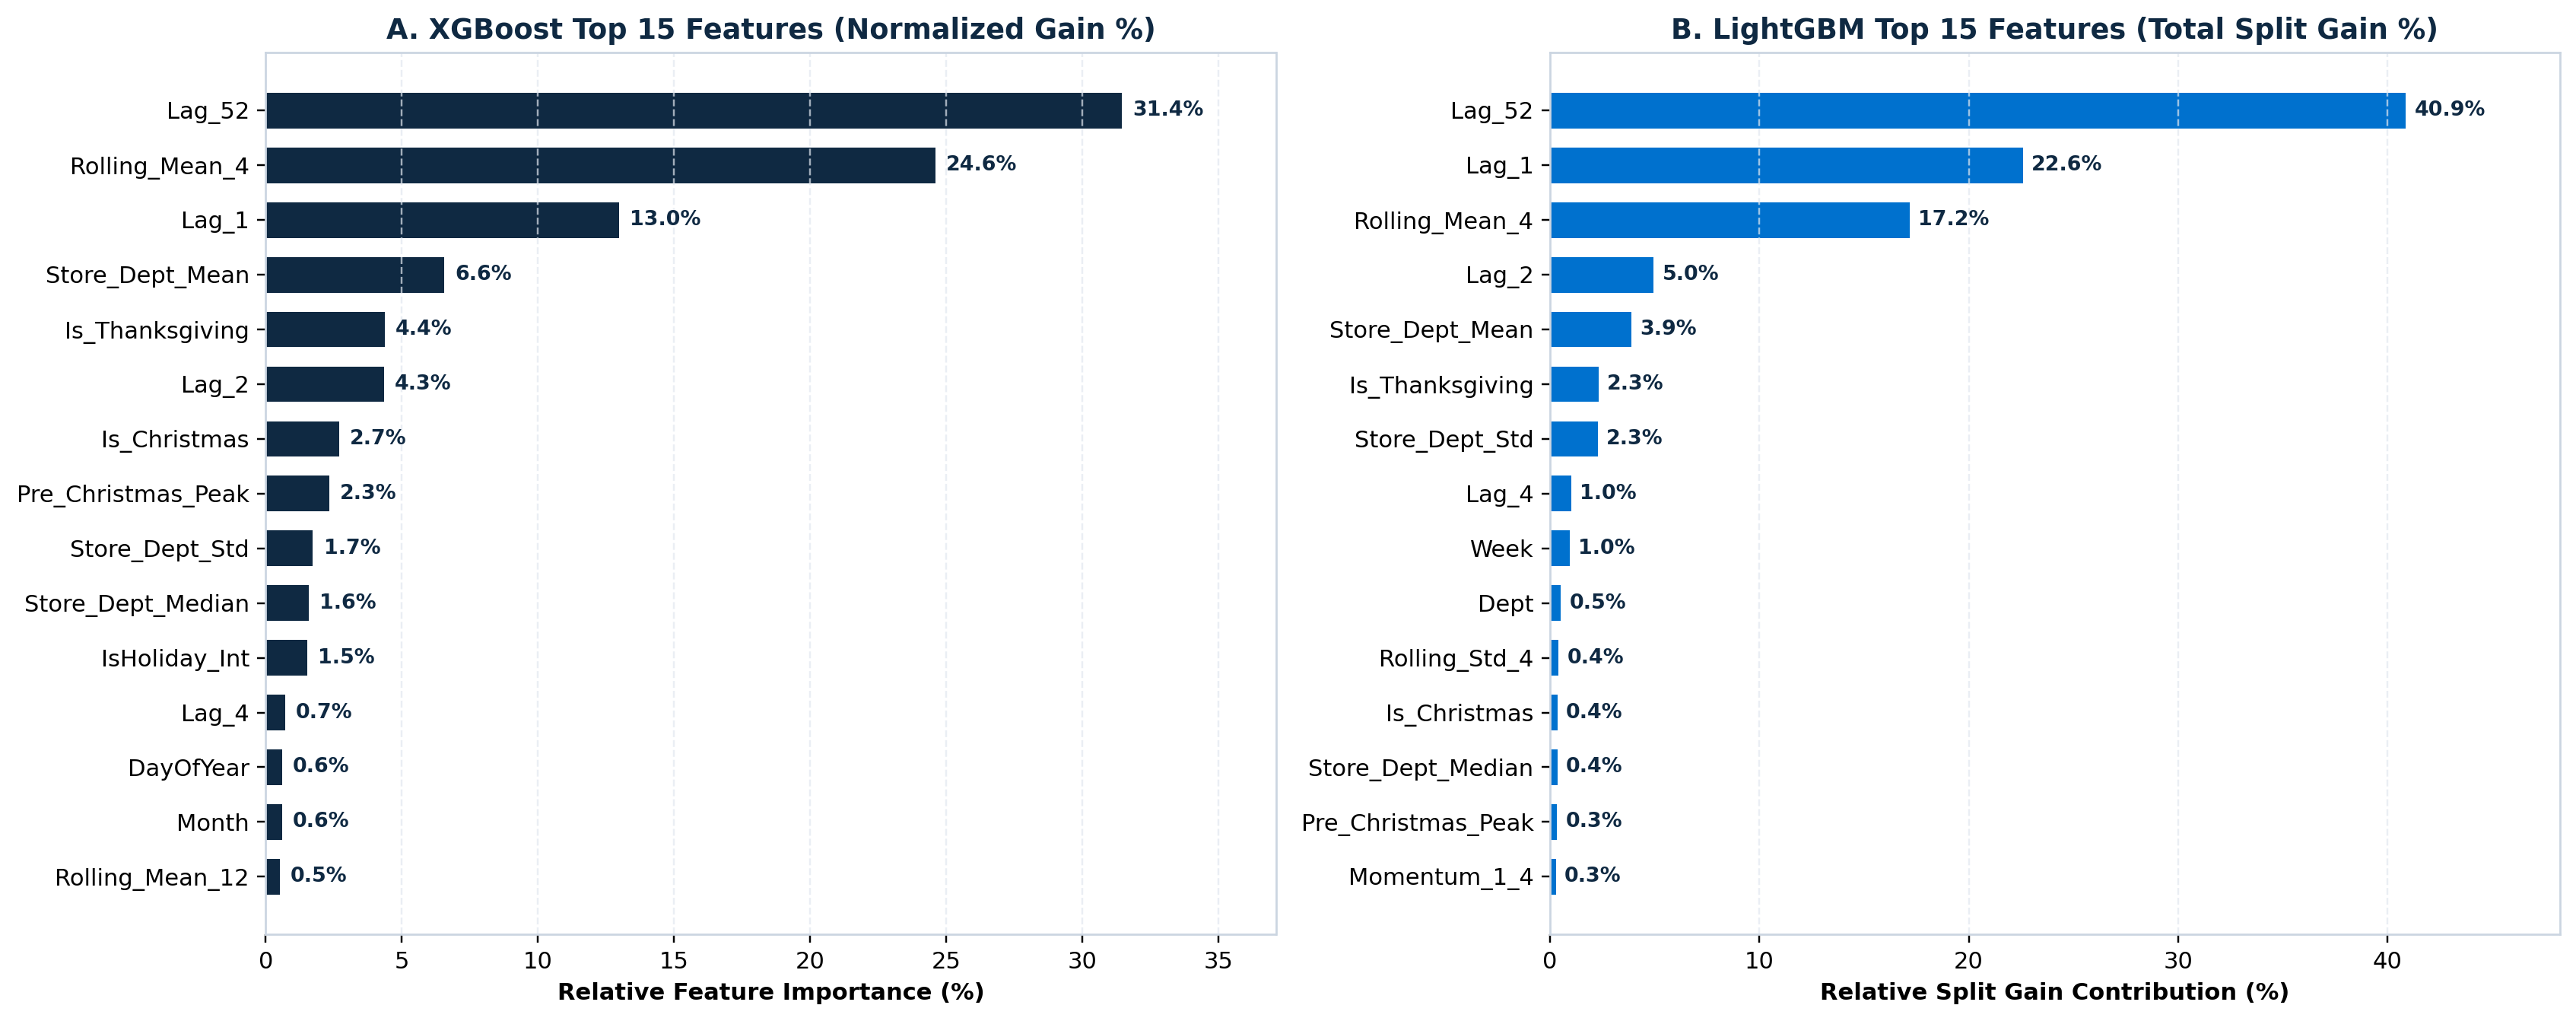

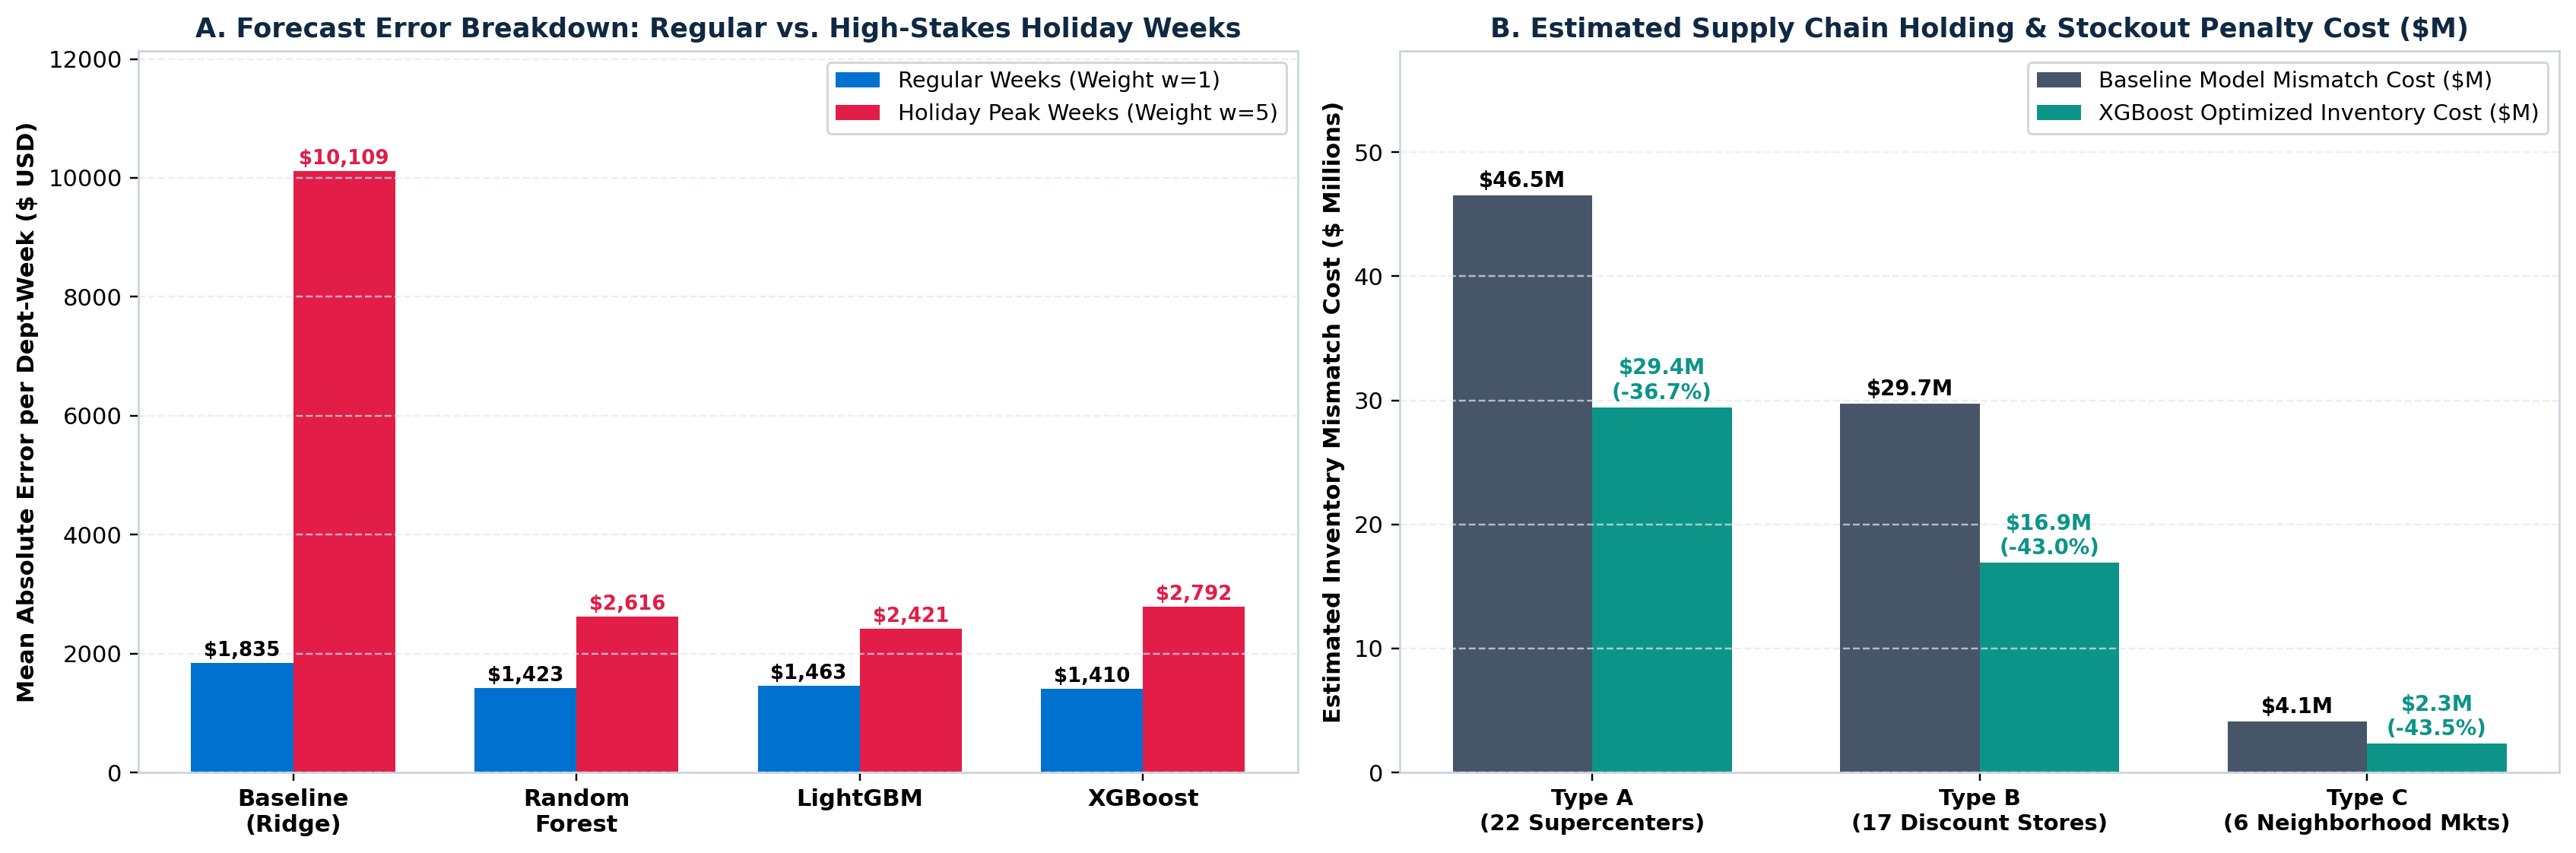

In [6]:
# Display Feature Importance Attribution and Supply Chain Cost Optimization Analysis
with open('outputs/metrics_summary.json') as f:
    summary = json.load(f)

top_features_df = pd.DataFrame({
    'XGBoost_Gain (%)': {k: round(v * 100, 2) for k, v in summary['top15_xgb'].items()},
    'LightGBM_Gain (%)': {k: round(v * 100, 2) for k, v in summary['top15_lgb'].items()},
    'RandomForest_Imp (%)': {k: round(v * 100, 2) for k, v in summary['top15_rf'].items()}
}).fillna(0.0).sort_values('XGBoost_Gain (%)', ascending=False)

print("=== Top Predictive Features by Relative Gain Attribution (%) ===")
print(top_features_df.head(12).to_string())

display(Image(filename='figures/fig7_feature_importance.png'))
display(Image(filename='figures/fig8_supply_chain_impact.png'))